In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(mean_absolute_error,mean_squared_error,r2_score,
accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

In [114]:

df=pd.read_csv("CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv")
df

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,2023-01-01 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,2023-01-02 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,2023-01-03 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,2023-01-04 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,2023-01-05 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13385,2026-08-31 00:00:00,Chisapani,Karnali,Karnali,280.00,28.653056,81.286944,2215,16.3,0.392,16.3,28.3,26.2,21,89,7.1,27.7,90,2.22
13386,2026-08-31 00:00:00,Devghat,Narayani,Narayani/Gandak,450.00,27.710000,84.430000,603,42.8,0.361,42.8,28.3,26.5,22,91,9.1,24.8,89,4.43
13387,2026-08-31 00:00:00,Khokana,Bagmati,Bagmati,550.05,27.632222,85.293333,1315,29.8,0.412,29.8,23.4,21.8,17,92,6.9,20.9,317,4.09
13388,2026-08-31 00:00:00,Kusum,West Rapti,Rapti,375.00,28.007500,82.093889,230,20.3,0.419,20.3,27.7,26.3,18,93,9.6,28.8,87,621.30


In [115]:
df.shape

(13390, 19)

In [116]:
df.head()

,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s
0,2023-01-01 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,12.2,-2.6,0,37,13.9,68.0,187,0.22
1,2023-01-02 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.315,0.0,11.1,-4.8,0,34,13.4,69.8,191,0.21
2,2023-01-03 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,11.5,-10.3,0,22,14.5,72.0,183,0.21
3,2023-01-04 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,9.6,-8.9,0,29,11.2,67.7,187,0.20
4,2023-01-05 00:00:00,Rasuwagadhi,Bhote Koshi,Narayani,446.22,28.271297,85.377649,1749,0.0,0.314,0.0,10.1,-10.2,0,26,7.4,69.8,54,0.20


Identify the target variable for the prediction

In [117]:
target_variable="river_discharge_m3s"
print("Target variable:",target_variable)

Target variable: river_discharge_m3s


Identify the numerical and categorical variables

In [118]:
categorical_columns=df.select_dtypes(include=["object","category"]).columns.tolist()
numerical_columns=df.select_dtypes(include=np.number).columns.tolist()
print("Categorical columns:",categorical_columns)
print("Numerical columns:",numerical_columns)

Categorical columns: ['date', 'location', 'river', 'basin']
Numerical columns: ['dhm_station', 'latitude', 'longitude', 'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c', 'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'river_discharge_m3s']


In [119]:
df.dtypes

date                            object
location                        object
river                           object
basin                           object
dhm_station                    float64
latitude                       float64
longitude                      float64
elevation_m                      int64
precipitation_mm               float64
soil_moisture_0_100cm_m3m3     float64
rain_mm                        float64
temperature_mean_c             float64
dew_point_mean_c               float64
precipitation_hours              int64
relative_humidity_mean_pct       int64
wind_speed_max_kmh             float64
wind_gusts_max_kmh             float64
wind_direction_dominant_deg      int64
river_discharge_m3s            float64
dtype: object

Check the dataset for missing values and duplicate records

In [120]:
print("Total missing values:",df.isnull().sum().sum())
print("Duplicate records:",df.duplicated().sum())

Total missing values: 0
Duplicate records: 0


Convert date into date formate


In [121]:
df["date"]=pd.to_datetime(df["date"],errors="coerce")

In [122]:
df['date'].isnull().sum()

np.int64(0)

In [123]:
df.dtypes

date                           datetime64[ns]
location                               object
river                                  object
basin                                  object
dhm_station                           float64
latitude                              float64
longitude                             float64
elevation_m                             int64
precipitation_mm                      float64
soil_moisture_0_100cm_m3m3            float64
rain_mm                               float64
temperature_mean_c                    float64
dew_point_mean_c                      float64
precipitation_hours                     int64
relative_humidity_mean_pct              int64
wind_speed_max_kmh                    float64
wind_gusts_max_kmh                    float64
wind_direction_dominant_deg             int64
river_discharge_m3s                   float64
dtype: object

Analyze the distribution of the river discharge variable

In [124]:
print("River discharge statistical summary:")
display(df["river_discharge_m3s"].describe())

River discharge statistical summary:


count    13390.000000
mean        20.372064
std         84.333629
min          0.000000
25%          0.260000
50%          1.880000
75%         10.530000
max       3175.870000
Name: river_discharge_m3s, dtype: float64

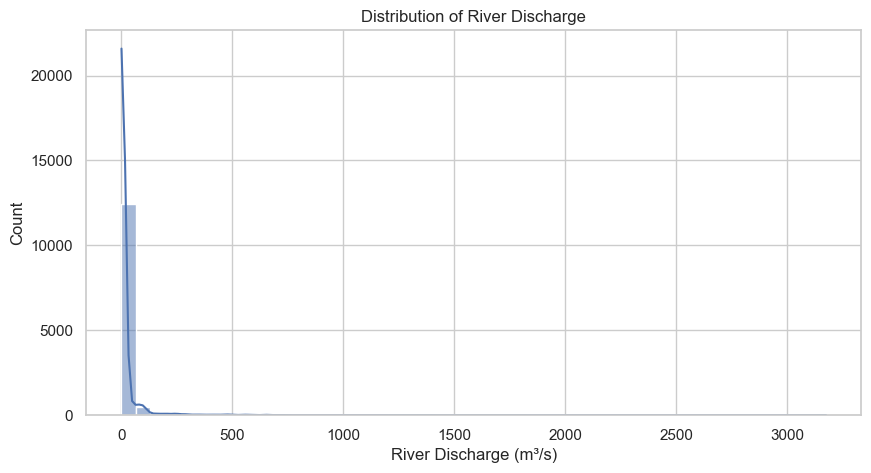

In [125]:
plt.figure(figsize=(10,5))
sns.histplot(df["river_discharge_m3s"],bins=50,kde=True)
plt.title("Distribution of River Discharge")
plt.xlabel("River Discharge (m³/s)")
plt.show()

Identify the river station/location with the highest average river discharge

In [126]:

location_summary=df.groupby("location")["river_discharge_m3s"].agg(["mean","median","max","count"])
location_summary=location_summary.sort_values("mean",ascending=False)

display(location_summary)
print("Highest average discharge location:",location_summary["mean"].idxmax())

,mean,median,max,count
location,,,,
Kusum,125.812158,16.86,3175.87,1339
Belsot,33.032636,11.42,255.45,1339
Chameliya/Nayalbadi,31.393465,14.14,124.60,1339
Bahrabise,5.051314,1.56,33.75,1339
Devghat,2.331277,0.86,20.78,1339
Khokana,1.658006,0.22,57.61,1339
Chatara,1.491344,0.28,23.27,1339
Rasuwagadhi,1.406751,0.63,8.33,1339
Chisapani,0.847072,0.26,16.99,1339


Highest average discharge location: Kusum


Analyze the relationship between rainfall/precipitation and river discharge

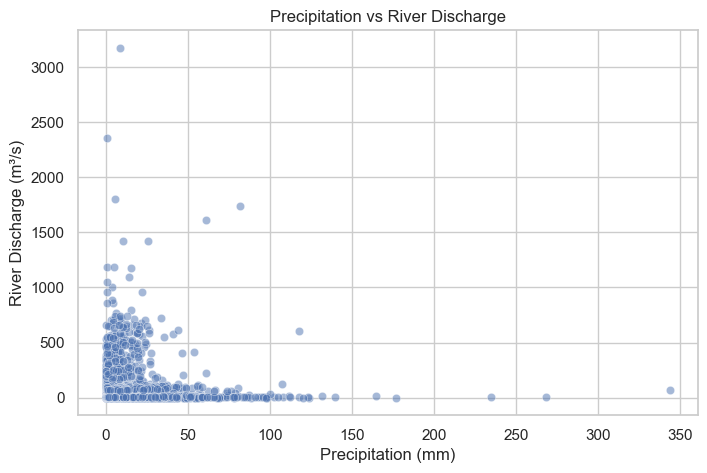

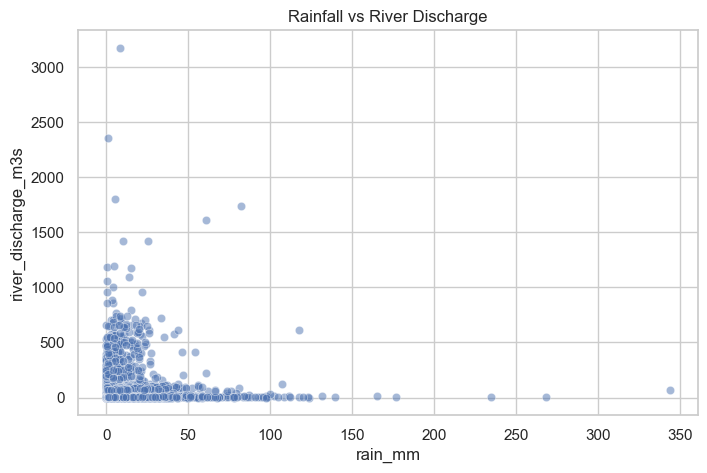

In [127]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x="precipitation_mm",y="river_discharge_m3s",alpha=0.5)
plt.title("Precipitation vs River Discharge")
plt.xlabel("Precipitation (mm)")
plt.ylabel("River Discharge (m³/s)")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="rain_mm",y="river_discharge_m3s",alpha=0.5)
plt.title("Rainfall vs River Discharge")
plt.show()

Identify which weather variable has the strongest relationship with river discharge

In [128]:
weather_columns=[
    "precipitation_mm",
    "rain_mm",
    "soil_moisture_0_100cm_m3m3",
    "temperature_mean_c",
    "dew_point_mean_c",
    "precipitation_hours",
    "relative_humidity_mean_pct",
    "wind_speed_max_kmh",
    "wind_gusts_max_kmh",
    "wind_direction_dominant_deg"]

correlations=df[weather_columns+["river_discharge_m3s"]
].corr(numeric_only=True)["river_discharge_m3s"].drop("river_discharge_m3s")

correlations=correlations.sort_values(key=abs,ascending=False)
display(correlations.to_frame("Correlation"))
print("Strongest absolute weather correlation:")
print(correlations.index[0], correlations.iloc[0])

,Correlation
dew_point_mean_c,0.226308
temperature_mean_c,0.178499
relative_humidity_mean_pct,0.171687
soil_moisture_0_100cm_m3m3,0.151942
precipitation_hours,0.145097
rain_mm,0.099743
precipitation_mm,0.098626
wind_speed_max_kmh,0.051560
wind_direction_dominant_deg,-0.040901
wind_gusts_max_kmh,-0.009484


Strongest absolute weather correlation:
dew_point_mean_c 0.22630797645176173


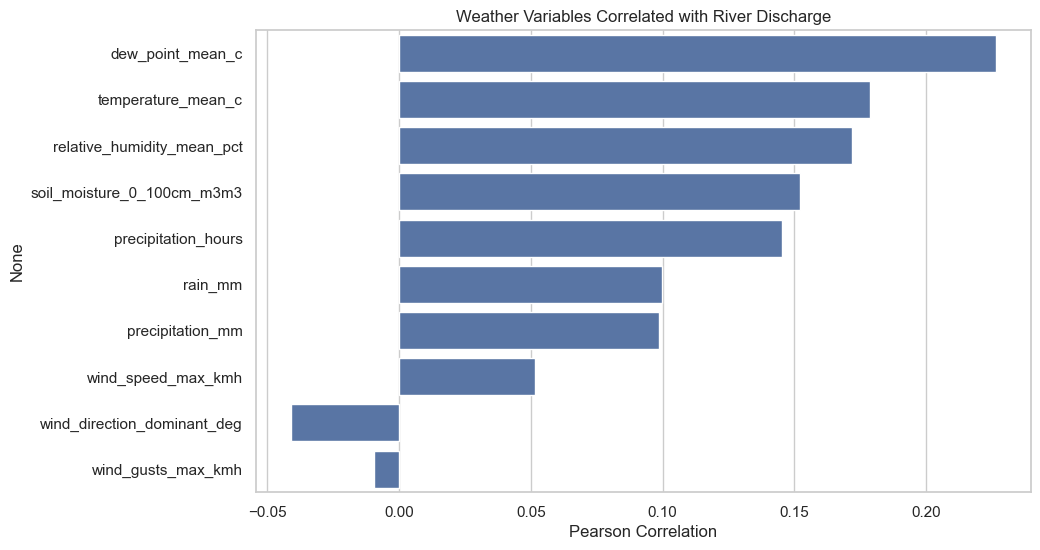

In [129]:
plt.figure(figsize=(10,6))
sns.barplot(x=correlations.values,y=correlations.index)
plt.title("Weather Variables Correlated with River Discharge")
plt.xlabel("Pearson Correlation")
plt.show()

Compare river discharge across different river stations/locations

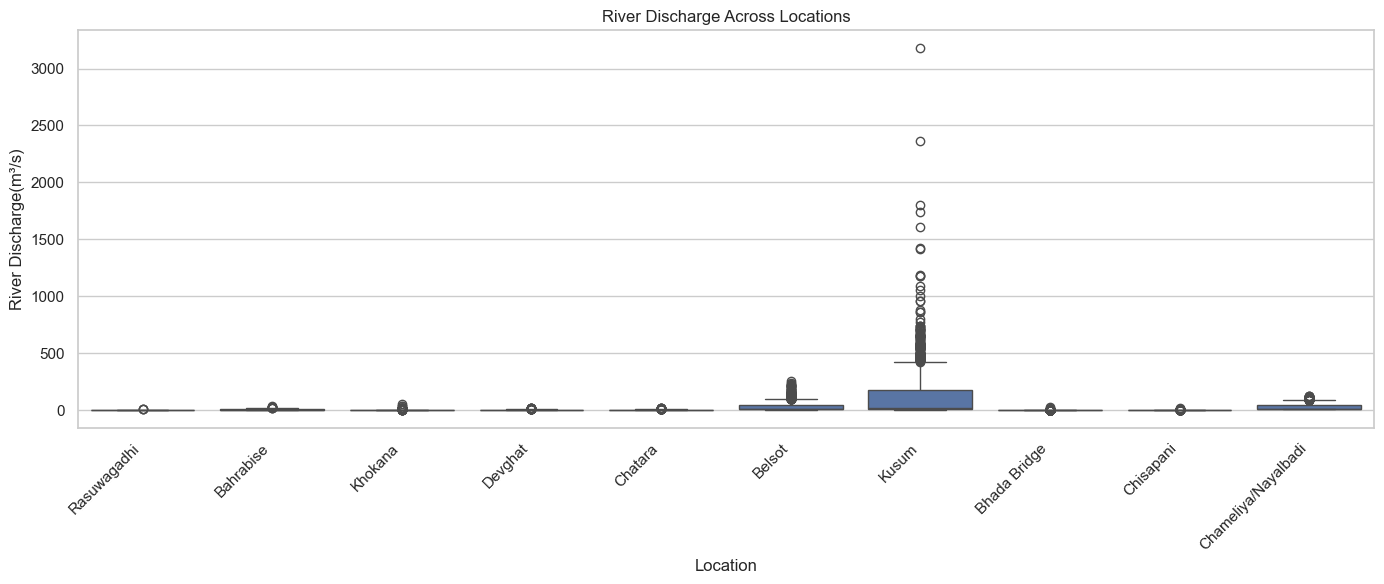

location
Kusum                  125.812158
Belsot                  33.032636
Chameliya/Nayalbadi     31.393465
Bahrabise                5.051314
Devghat                  2.331277
Khokana                  1.658006
Chatara                  1.491344
Rasuwagadhi              1.406751
Chisapani                0.847072
Bhada Bridge             0.696617
Name: river_discharge_m3s, dtype: float64

In [130]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df,x="location",y="river_discharge_m3s")
plt.xticks(rotation=45,ha="right")
plt.title("River Discharge Across Locations")
plt.xlabel("Location")
plt.ylabel("River Discharge(m³/s)")
plt.tight_layout()
plt.show()

display(df.groupby("location")["river_discharge_m3s"].mean().sort_values(ascending=False))

Analyze the monthly or seasonal pattern of river discharge

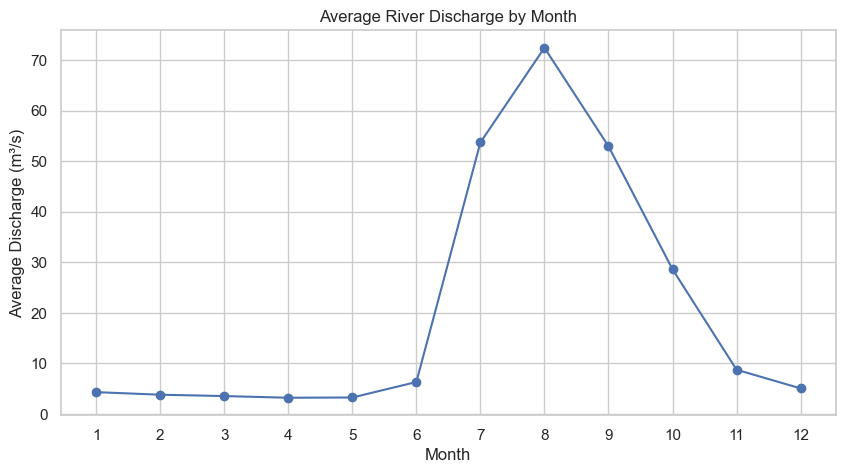

In [131]:
df["month"]=df["date"].dt.month
df["year"]=df["date"].dt.year

monthly_discharge=df.groupby("month")["river_discharge_m3s"].mean()
plt.figure(figsize=(10,5))
monthly_discharge.plot(marker="o")
plt.title("Average River Discharge by Month")
plt.xlabel("Month")
plt.ylabel("Average Discharge (m³/s)")
plt.xticks(range(1, 13))
plt.show()

In [132]:
# Nepal meteorological seasons:
# Winter:Dec-Feb,Pre-monsoon:Mar-May,
# Monsoon:Jun-Sep,Post-monsoon:Oct-Nov.

def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Pre-monsoon"
    elif month in [6,7,8,9]:
        return "Monsoon"
    else:
        return "Post-monsoon"


df["season"]=df["month"].apply(get_season)
seasonal_discharge=df.groupby("season")["river_discharge_m3s"].mean().sort_values(ascending=False)
display(seasonal_discharge.to_frame("Average Discharge"))

,Average Discharge
season,
Monsoon,46.226443
Post-monsoon,18.840557
Winter,4.343382
Pre-monsoon,3.329742


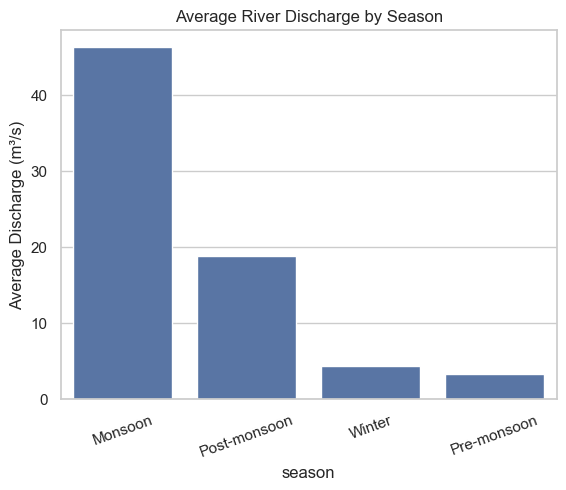

In [133]:
sns.barplot(x=seasonal_discharge.index,y=seasonal_discharge.values)
plt.title("Average River Discharge by Season")
plt.ylabel("Average Discharge (m³/s)")
plt.xticks(rotation=20)
plt.show()

Identify periods with unusually high river discharge

In [134]:
# Descriptive threshold: 95th percentile of observed discharge.
high_threshold=df["river_discharge_m3s"].quantile(0.95)
high_flow_records=df[df["river_discharge_m3s"]>=high_threshold].sort_values(
    "river_discharge_m3s", ascending=False)
print("95th percentile threshold:",high_threshold)
print("Number of unusually high discharge records:",len(high_flow_records))

display(high_flow_records[["date","location","river_discharge_m3s"]].head(20))

95th percentile threshold: 90.41
Number of unusually high discharge records: 673


,date,location,river_discharge_m3s
6368,2024-09-28,Kusum,3175.87
6378,2024-09-29,Kusum,2359.48
2374,2023-07-04,Kusum,1802.02
5538,2024-07-07,Kusum,1736.80
5528,2024-07-06,Kusum,1609.65
2371,2023-07-01,Kusum,1421.33
5548,2024-07-08,Kusum,1418.06
9568,2025-08-14,Kusum,1190.24
2375,2023-07-05,Kusum,1182.04
9478,2025-08-05,Kusum,1173.90


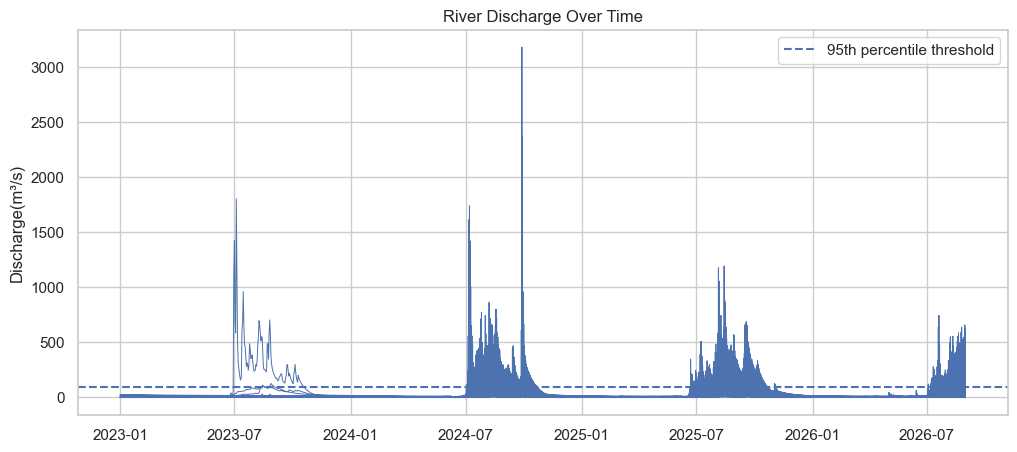

In [135]:
plt.figure(figsize=(12,5))
plt.plot(df["date"],df["river_discharge_m3s"],linewidth=0.7)
plt.axhline(high_threshold,linestyle="--",label="95th percentile threshold")
plt.title("River Discharge Over Time")
plt.ylabel("Discharge(m³/s)")
plt.legend()
plt.show()

Create lag features for rainfall, such as previous-day, previous 2-day, and previous 3-
day rainfall

In [136]:
df=df.sort_values(["location", "date"]).copy()

for col in ["rain_mm","precipitation_mm"]:
    for lag in [1,2,3]:
        df[f"{col}_lag{lag}"]=(
            df.groupby("location")[col].shift(lag))

display(df[[ "date","location","rain_mm",
             "rain_mm_lag1","rain_mm_lag2",
             "rain_mm_lag3"]].head(10))

,date,location,rain_mm,rain_mm_lag1,rain_mm_lag2,rain_mm_lag3
365,2023-01-01,Bahrabise,0.0,NaN,NaN,NaN
366,2023-01-02,Bahrabise,0.0,0.0,NaN,NaN
367,2023-01-03,Bahrabise,0.0,0.0,0.0,NaN
368,2023-01-04,Bahrabise,0.0,0.0,0.0,0.0
369,2023-01-05,Bahrabise,0.0,0.0,0.0,0.0
370,2023-01-06,Bahrabise,0.0,0.0,0.0,0.0
371,2023-01-07,Bahrabise,0.0,0.0,0.0,0.0
372,2023-01-08,Bahrabise,0.0,0.0,0.0,0.0
373,2023-01-09,Bahrabise,0.0,0.0,0.0,0.0
374,2023-01-10,Bahrabise,0.0,0.0,0.0,0.0


Create rolling rainfall features such as 3-day and 7-day rainfall totals/averages

In [137]:
for col in ["rain_mm","precipitation_mm"]:

    df[f"{col}_rolling3_sum"]=(df.groupby("location")[col]
        .transform(lambda s:s.rolling(3, min_periods=1).sum()))

    df[f"{col}_rolling7_sum"]=(df.groupby("location")[col]
        .transform(lambda s:s.rolling(7, min_periods=1).sum()))

    df[f"{col}_rolling3_mean"]=(df.groupby("location")[col]
        .transform(lambda s:s.rolling(3, min_periods=1).mean()))

display(df[[ "date","location","rain_mm",
             "rain_mm_rolling3_sum",
             "rain_mm_rolling7_sum",
             "rain_mm_rolling3_mean"]].head(10))

,date,location,rain_mm,rain_mm_rolling3_sum,rain_mm_rolling7_sum,rain_mm_rolling3_mean
365,2023-01-01,Bahrabise,0.0,0.0,0.0,0.0
366,2023-01-02,Bahrabise,0.0,0.0,0.0,0.0
367,2023-01-03,Bahrabise,0.0,0.0,0.0,0.0
368,2023-01-04,Bahrabise,0.0,0.0,0.0,0.0
369,2023-01-05,Bahrabise,0.0,0.0,0.0,0.0
370,2023-01-06,Bahrabise,0.0,0.0,0.0,0.0
371,2023-01-07,Bahrabise,0.0,0.0,0.0,0.0
372,2023-01-08,Bahrabise,0.0,0.0,0.0,0.0
373,2023-01-09,Bahrabise,0.0,0.0,0.0,0.0
374,2023-01-10,Bahrabise,0.0,0.0,0.0,0.0


Create previous-day river discharge features

In [138]:
for lag in [1,2,3]:
    df[f"discharge_lag{lag}"]=(df.groupby("location")[ "river_discharge_m3s"].shift(lag))

display(df[["date", "location", "river_discharge_m3s",
            "discharge_lag1", "discharge_lag2",
            "discharge_lag3"]].head(10))

,date,location,river_discharge_m3s,discharge_lag1,discharge_lag2,discharge_lag3
365,2023-01-01,Bahrabise,1.05,NaN,NaN,NaN
366,2023-01-02,Bahrabise,1.05,1.05,NaN,NaN
367,2023-01-03,Bahrabise,1.01,1.05,1.05,NaN
368,2023-01-04,Bahrabise,0.99,1.01,1.05,1.05
369,2023-01-05,Bahrabise,0.97,0.99,1.01,1.05
370,2023-01-06,Bahrabise,0.95,0.97,0.99,1.01
371,2023-01-07,Bahrabise,0.94,0.95,0.97,0.99
372,2023-01-08,Bahrabise,0.94,0.94,0.95,0.97
373,2023-01-09,Bahrabise,0.92,0.94,0.94,0.95
374,2023-01-10,Bahrabise,0.92,0.92,0.94,0.94


Extract useful date features such as year and month

In [139]:
df["year"]=df["date"].dt.year
df["month"]=df["date"].dt.month
df["day"]=df["date"].dt.day
df["day_of_year"]=df["date"].dt.dayofyear
df["day_of_week"]=df["date"].dt.dayofweek

# Cyclical encoding represents the repeating annual month pattern.
df["month_sin"]=np.sin(2*np.pi*df["month"]/12)
df["month_cos"]=np.cos(2*np.pi*df["month"]/12)

display(df[["date", "year", "month", "day",
            "day_of_year", "day_of_week",
            "month_sin", "month_cos"]].head())

,date,year,month,day,day_of_year,day_of_week,month_sin,month_cos
365,2023-01-01,2023,1,1,1,6,0.5,0.866025
366,2023-01-02,2023,1,2,2,0,0.5,0.866025
367,2023-01-03,2023,1,3,3,1,0.5,0.866025
368,2023-01-04,2023,1,4,4,2,0.5,0.866025
369,2023-01-05,2023,1,5,5,3,0.5,0.866025


Encode the river station/location variable for machine learning

In [140]:
print("Available locations:")
print(sorted(df["location"].dropna().unique()))

# Demonstration of one-hot encoding
location_encoded=pd.get_dummies(df["location"],prefix="location",dtype=int)
display(location_encoded.head())

# The actual ML models will perform encoding automatically
# inside the preprocessing pipeline

Available locations:
['Bahrabise', 'Belsot', 'Bhada Bridge', 'Chameliya/Nayalbadi', 'Chatara', 'Chisapani', 'Devghat', 'Khokana', 'Kusum', 'Rasuwagadhi']


,location_Bahrabise,location_Belsot,location_Bhada Bridge,location_Chameliya/Nayalbadi,location_Chatara,location_Chisapani,location_Devghat,location_Khokana,location_Kusum,location_Rasuwagadhi
365,1,0,0,0,0,0,0,0,0,0
366,1,0,0,0,0,0,0,0,0,0
367,1,0,0,0,0,0,0,0,0,0
368,1,0,0,0,0,0,0,0,0,0
369,1,0,0,0,0,0,0,0,0,0


Create the target variable as the next day's river discharge

In [141]:
df=df.sort_values(["location", "date"]).copy()
df["target_next_day"]=(df.groupby("location")["river_discharge_m3s"].shift(-1))
df["target_date"]=(df.groupby("location")["date"].shift(-1))
display(df[["date","target_date","location","river_discharge_m3s","target_next_day"]].head(10))

,date,target_date,location,river_discharge_m3s,target_next_day
365,2023-01-01,2023-01-02,Bahrabise,1.05,1.05
366,2023-01-02,2023-01-03,Bahrabise,1.05,1.01
367,2023-01-03,2023-01-04,Bahrabise,1.01,0.99
368,2023-01-04,2023-01-05,Bahrabise,0.99,0.97
369,2023-01-05,2023-01-06,Bahrabise,0.97,0.95
370,2023-01-06,2023-01-07,Bahrabise,0.95,0.94
371,2023-01-07,2023-01-08,Bahrabise,0.94,0.94
372,2023-01-08,2023-01-09,Bahrabise,0.94,0.92
373,2023-01-09,2023-01-10,Bahrabise,0.92,0.92
374,2023-01-10,2023-01-11,Bahrabise,0.92,0.91


Prepare the input features using weather conditions, historical discharge, date 
features, and location

In [142]:
excluded_columns=["date","target_date","target_next_day","river_discharge_m3s","month","year",
                  "day","season"]
feature_columns=[col for col in df.columns if col not in excluded_columns]
model_df=df.dropna(subset=["target_next_day","target_date", "discharge_lag1","discharge_lag2",
                            "discharge_lag3"]).copy()
X=model_df[feature_columns].copy()
y=model_df["target_next_day"].copy()
print("Feature count:",len(feature_columns))
print("Features:",feature_columns)
print("X shape:",X.shape)
print("y shape:",y.shape)

Feature count: 36
Features: ['location', 'river', 'basin', 'dhm_station', 'latitude', 'longitude', 'elevation_m', 'precipitation_mm', 'soil_moisture_0_100cm_m3m3', 'rain_mm', 'temperature_mean_c', 'dew_point_mean_c', 'precipitation_hours', 'relative_humidity_mean_pct', 'wind_speed_max_kmh', 'wind_gusts_max_kmh', 'wind_direction_dominant_deg', 'rain_mm_lag1', 'rain_mm_lag2', 'rain_mm_lag3', 'precipitation_mm_lag1', 'precipitation_mm_lag2', 'precipitation_mm_lag3', 'rain_mm_rolling3_sum', 'rain_mm_rolling7_sum', 'rain_mm_rolling3_mean', 'precipitation_mm_rolling3_sum', 'precipitation_mm_rolling7_sum', 'precipitation_mm_rolling3_mean', 'discharge_lag1', 'discharge_lag2', 'discharge_lag3', 'day_of_year', 'day_of_week', 'month_sin', 'month_cos']
X shape: (13350, 36)
y shape: (13350,)


Split the data into training and testing sets using an appropriate time-based approach\

In [143]:
unique_dates=np.sort(model_df["target_date"].dropna().unique())

split_index=int(len(unique_dates)*0.80)
split_date=pd.Timestamp(unique_dates[split_index])

train_df=model_df[model_df["target_date"]<split_date].copy()

test_df=model_df[model_df["target_date"]>=split_date].copy()

X_train=train_df[feature_columns]
X_test=test_df[feature_columns]

y_train=train_df["target_next_day"]
y_test=test_df["target_next_day"]

print("Split date:",split_date)
print("Training rows:",len(X_train))
print("Testing rows:",len(X_test))

print("Training target dates:",
      train_df["target_date"].min(),
      "to",train_df["target_date"].max())

print("Testing target dates:",
      test_df["target_date"].min(),
      "to",test_df["target_date"].max())

Split date: 2025-12-08 00:00:00
Training rows: 10680
Testing rows: 2670
Training target dates: 2023-01-05 00:00:00 to 2025-12-07 00:00:00
Testing target dates: 2025-12-08 00:00:00 to 2026-08-31 00:00:00


Explain why a time-based split is appropriate for this dataset

In [144]:
print("""
A time-based split is appropriate because the objective is to
predict future river discharge.

The model trains on earlier observations and is tested on later
observations. A random split could mix future and past records
and make performance appear better than it really is.

The split uses target_date so the date being predicted determines
whether a record belongs to training or testing.
""")


A time-based split is appropriate because the objective is to
predict future river discharge.

The model trains on earlier observations and is tested on later
observations. A random split could mix future and past records
and make performance appear better than it really is.

The split uses target_date so the date being predicted determines
whether a record belongs to training or testing.



Train a Linear Regression model

In [145]:
categorical_features=X_train.select_dtypes(include=["object","category"]).columns.tolist()
numeric_features=[col for col in X_train.columns if col not in categorical_features]

try:
    onehot=OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False)
except TypeError:
    onehot=OneHotEncoder(
        handle_unknown="ignore",
        sparse=False)

preprocessor=ColumnTransformer(
transformers=[("num",
            Pipeline([
                ("imputer",SimpleImputer(strategy="median"))]),
            numeric_features),
        ("cat",
            Pipeline([
                ("imputer",SimpleImputer(strategy="most_frequent")),
                ("encoder",onehot)]),
            categorical_features)])

linear_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LinearRegression())])

linear_model.fit(X_train, y_train)
linear_predictions=linear_model.predict(X_test)
print("Linear Regression training completed.")

Linear Regression training completed.


Train a Random Forest Regressor

In [146]:
random_forest_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
rf_predictions=random_forest_model.predict(X_test)
print("Random Forest training completed.")

Random Forest training completed.


Train at least one additional regression algorithm such as Decision Tree, Gradient 
Boosting, or XGBoost

Train Gradient Boosting Regressor


In [147]:
gradient_boosting_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)
gb_predictions=gradient_boosting_model.predict(X_test)
print("Gradient Boosting training completed.")

Gradient Boosting training completed.


Compare the models using MAE, MSE, RMSE, and R² Score

In [148]:
models={
    "Linear Regression":(linear_model, linear_predictions),
    "Random Forest":(random_forest_model, rf_predictions),
    "Gradient Boosting":(gradient_boosting_model, gb_predictions)
}
regression_results=[]

for name,(model,predictions) in models.items():

    mse=mean_squared_error(y_test, predictions)

    regression_results.append({
        "Model":name,
        "MAE":mean_absolute_error(y_test, predictions),
        "MSE":mse,
        "RMSE":np.sqrt(mse),
        "R2":r2_score(y_test, predictions)
    })

regression_results=pd.DataFrame(regression_results).sort_values("RMSE")
display(regression_results)

,Model,MAE,MSE,RMSE,R2
2,Gradient Boosting,4.158856,593.713782,24.366243,0.828520
0,Linear Regression,11.659612,606.482933,24.626874,0.824832
1,Random Forest,3.816623,731.510278,27.046447,0.788721


Identify the best-performing model and explain why it was selected

In [149]:
best_model_name=regression_results.iloc[0]["Model"]
best_model=models[best_model_name][0]
best_predictions=models[best_model_name][1]
print("Best model based on lowest test RMSE:",best_model_name)

print("""
RMSE measures the typical prediction error in the same units
as river discharge. Lower RMSE indicates smaller errors.

MAE, MSE and R² should also be checked before deciding whether
the selected model is suitable for the forecasting task.
""")

Best model based on lowest test RMSE: Gradient Boosting

RMSE measures the typical prediction error in the same units
as river discharge. Lower RMSE indicates smaller errors.

MAE, MSE and R² should also be checked before deciding whether
the selected model is suitable for the forecasting task.



Create an Actual vs Predicted River Discharge visualization

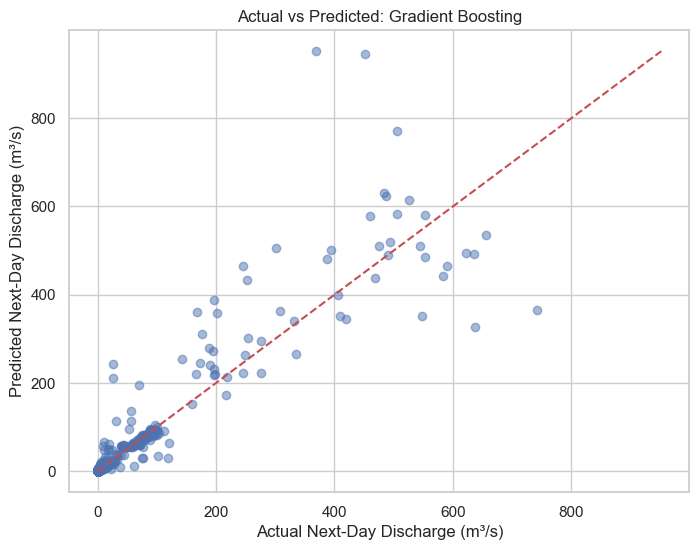

In [150]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test,best_predictions,alpha=0.5)

lower=min(y_test.min(),best_predictions.min())
upper=max(y_test.max(),best_predictions.max())
plt.plot([lower, upper],[lower, upper],"r--")

plt.xlabel("Actual Next-Day Discharge (m³/s)")
plt.ylabel("Predicted Next-Day Discharge (m³/s)")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.show()

Analyze the prediction errors of the best-performing model

Error summary:


count    2670.000000
mean       -1.346059
std        24.333592
min      -583.891000
25%        -1.202766
50%        -0.629630
75%         0.676762
max       376.570961
Name: error, dtype: float64

Largest absolute prediction errors:


,date,target_date,location,target_next_day,actual,predicted,error,absolute_error
13228,2026-08-15,2026-08-16,Kusum,367.98,367.98,951.871000,-583.891000,583.891000
13238,2026-08-16,2026-08-17,Kusum,450.86,450.86,945.649205,-494.789205,494.789205
12958,2026-07-19,2026-07-20,Kusum,742.02,742.02,365.449039,376.570961,376.570961
12948,2026-07-18,2026-07-19,Kusum,637.26,637.26,326.411444,310.848556,310.848556
13248,2026-08-17,2026-08-18,Kusum,505.99,505.99,771.661317,-265.671317,265.671317
12888,2026-07-12,2026-07-13,Kusum,245.04,245.04,464.244621,-219.204621,219.204621
12188,2026-05-03,2026-05-04,Kusum,26.16,26.16,242.255670,-216.095670,216.095670
12978,2026-07-21,2026-07-22,Kusum,301.69,301.69,506.137242,-204.447242,204.447242
13138,2026-08-06,2026-08-07,Kusum,548.54,548.54,352.649230,195.890770,195.890770
12898,2026-07-13,2026-07-14,Kusum,196.70,196.70,388.833913,-192.133913,192.133913


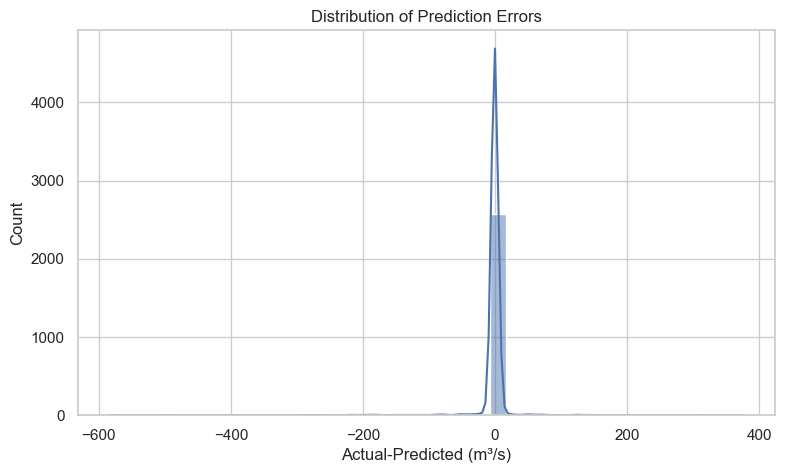

In [151]:
evaluation=test_df[["date","target_date","location","target_next_day"]].copy()

evaluation["actual"]=y_test.to_numpy()
evaluation["predicted"]=best_predictions
evaluation["error"]=(evaluation["actual"]-evaluation["predicted"])
evaluation["absolute_error"] = evaluation["error"].abs()

print("Error summary:")
display(evaluation["error"].describe())

print("Largest absolute prediction errors:")
display(evaluation.sort_values("absolute_error",ascending=False).head(20))

plt.figure(figsize=(9,5))
sns.histplot(evaluation["error"],bins=40,kde=True)
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual-Predicted (m³/s)")
plt.show()

Identify the dates/locations where the model made the largest prediction errors

In [152]:
largest_errors=evaluation.sort_values("absolute_error",ascending=False).head(20)
display(largest_errors[["target_date","location","actual","predicted","error","absolute_error"]])
largest_error_row=largest_errors.iloc[0]

print("Largest error date:",largest_error_row["target_date"])
print("Location:",largest_error_row["location"])
print("Actual discharge:",largest_error_row["actual"])
print("Predicted discharge:",largest_error_row["predicted"])
print("Absolute error:",largest_error_row["absolute_error"])

,target_date,location,actual,predicted,error,absolute_error
13228,2026-08-16,Kusum,367.98,951.871000,-583.891000,583.891000
13238,2026-08-17,Kusum,450.86,945.649205,-494.789205,494.789205
12958,2026-07-20,Kusum,742.02,365.449039,376.570961,376.570961
12948,2026-07-19,Kusum,637.26,326.411444,310.848556,310.848556
13248,2026-08-18,Kusum,505.99,771.661317,-265.671317,265.671317
12888,2026-07-13,Kusum,245.04,464.244621,-219.204621,219.204621
12188,2026-05-04,Kusum,26.16,242.255670,-216.095670,216.095670
12978,2026-07-22,Kusum,301.69,506.137242,-204.447242,204.447242
13138,2026-08-07,Kusum,548.54,352.649230,195.890770,195.890770
12898,2026-07-14,Kusum,196.70,388.833913,-192.133913,192.133913


Largest error date: 2026-08-16 00:00:00
Location: Kusum
Actual discharge: 367.98
Predicted discharge: 951.8709997984776
Absolute error: 583.8909997984775


Identify the most important features affecting river discharge prediction

In [153]:
fitted_preprocessor=best_model.named_steps["preprocessor"]
fitted_estimator=best_model.named_steps["model"]
feature_names=fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator,"feature_importances_"):
    importance_values=fitted_estimator.feature_importances_
    feature_importance=pd.DataFrame({"Feature":feature_names,"Importance":importance_values
                                     }).sort_values("Importance", ascending=False)
elif hasattr(fitted_estimator,"coef_"):
    feature_importance=pd.DataFrame({"Feature": feature_names,
                                     "Importance": np.abs(fitted_estimator.coef_)
    }).sort_values("Importance",ascending=False)
display(feature_importance.head(20))

,Feature,Importance
26,num__discharge_lag1,0.699207
22,num__rain_mm_rolling3_mean,0.049866
4,num__precipitation_mm,0.041742
6,num__rain_mm,0.033366
23,num__precipitation_mm_rolling3_sum,0.027714
7,num__temperature_mean_c,0.024802
29,num__day_of_year,0.018615
27,num__discharge_lag2,0.017293
20,num__rain_mm_rolling3_sum,0.014511
25,num__precipitation_mm_rolling3_mean,0.012647


Create a feature importance visualization for the best model

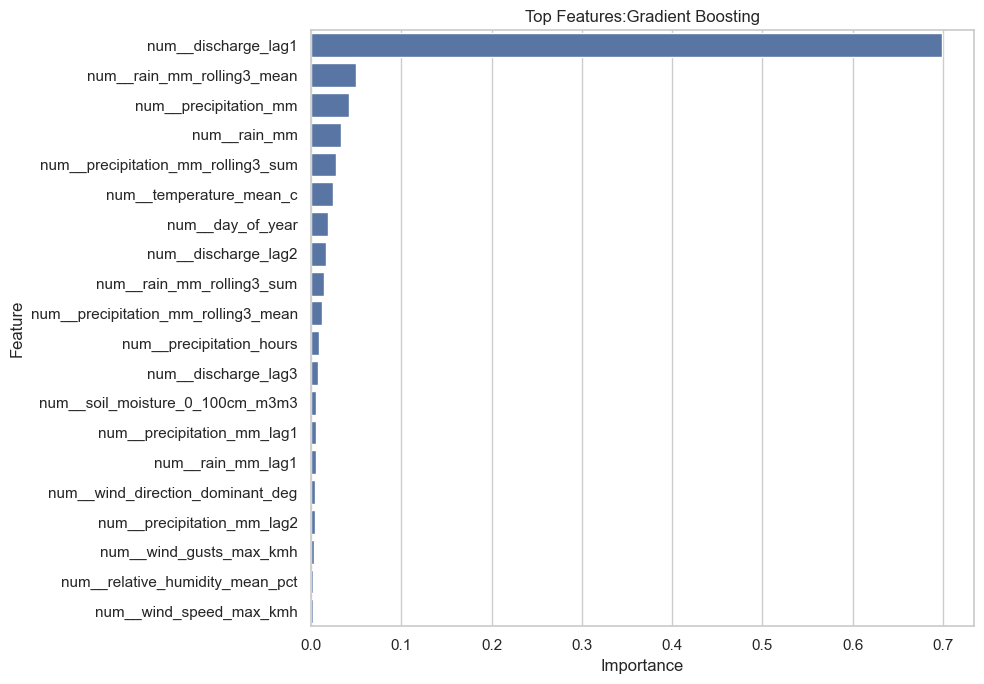

In [154]:
top_features=feature_importance.head(20)
plt.figure(figsize=(10, 7))
sns.barplot(data=top_features,x="Importance",y="Feature")
plt.title(f"Top Features:{best_model_name}")
plt.tight_layout()
plt.show()

Compare model performance before and after feature engineering

In [155]:
baseline_excluded={"date","target_date","target_next_day","river_discharge_m3s","month",
                      "year","day","season"}

engineered_features=feature_columns
baseline_features=[c for c in engineered_features
    if not any(token in c.lower()
        for token in ["_lag","_rolling","discharge_lag","month_sin","month_cos", 
                      "day_of_year","day_of_week"])]

X_train_base=train_df[baseline_features]
X_test_base=test_df[baseline_features]

base_cat=X_train_base.select_dtypes(include=["object", "category"]).columns.tolist()
base_num=[c for c in baseline_features if c not in base_cat]

base_preprocessor=ColumnTransformer([("num",SimpleImputer(strategy="median"),base_num),
                             ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                            ("encoder",OneHotEncoder(handle_unknown="ignore"))]), base_cat)])

baseline_model=Pipeline([("preprocessor",base_preprocessor),
                         ("model", RandomForestRegressor(n_estimators=200,
                                                         min_samples_leaf=2,
                                                         random_state=42,
                                                         n_jobs=-1))])

baseline_model.fit(X_train_base, y_train)
baseline_predictions=baseline_model.predict(X_test_base)

baseline_rmse=np.sqrt(mean_squared_error(y_test,baseline_predictions))
engineered_rmse=np.sqrt(mean_squared_error(y_test,best_predictions))
improvement=((baseline_rmse-engineered_rmse) / baseline_rmse * 100
    if baseline_rmse !=0 else np.nan)
print("Baseline RMSE:",baseline_rmse)
print("Best engineered model RMSE:",engineered_rmse)
print("RMSE improvement (%):",improvement)

Baseline RMSE: 28.22159228685247
Best engineered model RMSE: 24.366242679930803
RMSE improvement (%): 13.660992504373151


Create a High Flow = 1 and Normal Flow = 0 target

In [156]:
station_thresholds=train_df.groupby("location")["target_next_day"].quantile(0.90).to_dict()

classification_df=model_df.copy()
classification_df["high_flow_threshold"]=(classification_df["location"].map(station_thresholds))

classification_df["high_flow_next_day"]=(classification_df["target_next_day"]
                                         >= classification_df["high_flow_threshold"]).astype(int)

class_train=classification_df[classification_df["target_date"]<split_date].copy()
class_test=classification_df[classification_df["target_date"]>=split_date].copy()

Xc_train=class_train[feature_columns]
Xc_test=class_test[feature_columns]
yc_train=class_train["high_flow_next_day"]
yc_test=class_test["high_flow_next_day"]

print("Station-specific thresholds:")
display(pd.Series(station_thresholds,name="Threshold(m³/s)"))
print("Training labels:")
display(yc_train.value_counts())
print("Testing labels:")
display(yc_test.value_counts())

Station-specific thresholds:


Bahrabise               13.669
Belsot                  94.566
Bhada Bridge             2.649
Chameliya/Nayalbadi     92.176
Chatara                  4.570
Chisapani                2.619
Devghat                  6.290
Khokana                  4.986
Kusum                  425.782
Rasuwagadhi              3.590
Name: Threshold(m³/s), dtype: float64

Training labels:


high_flow_next_day
0    9607
1    1073
Name: count, dtype: int64

Testing labels:


high_flow_next_day
0    2497
1     173
Name: count, dtype: int64

Handle any class imbalance appropriately

In [157]:
print("Training class distribution:")
print(yc_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(yc_test.value_counts(normalize=True))

# Use class_weight='balanced' for the classification models.
# This gives more weight to the minority class during training.
# We will evaluate recall and F1, not accuracy alone.

Training class distribution:
high_flow_next_day
0    0.899532
1    0.100468
Name: proportion, dtype: float64

Testing class distribution:
high_flow_next_day
0    0.935206
1    0.064794
Name: proportion, dtype: float64


Train Logistic Regression, Decision Tree, and Random Forest classification models

In [158]:
classifiers={"Logistic Regression":LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42),

    "Decision Tree":DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42),

    "Random Forest":RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1)}

fitted_classifiers={}
classification_predictions={}

for name,estimator in classifiers.items():

    pipeline=Pipeline([("preprocessor",preprocessor),("model",estimator)])
    pipeline.fit(Xc_train,yc_train)
    predictions=pipeline.predict(Xc_test)

    fitted_classifiers[name]=pipeline
    classification_predictions[name]=predictions
    print(name, "training completed.")

Logistic Regression training completed.
Decision Tree training completed.
Random Forest training completed.


Evaluate the models using Accuracy, Precision, Recall, F1-score, and a Confusion 
Matrix

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.957678,0.640187,0.791908,0.708010
1,Decision Tree,0.882772,0.352941,0.971098,0.517720
0,Logistic Regression,0.845693,0.295726,1.000000,0.456464


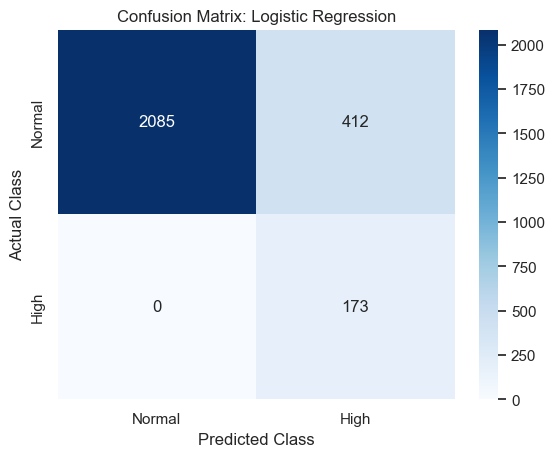

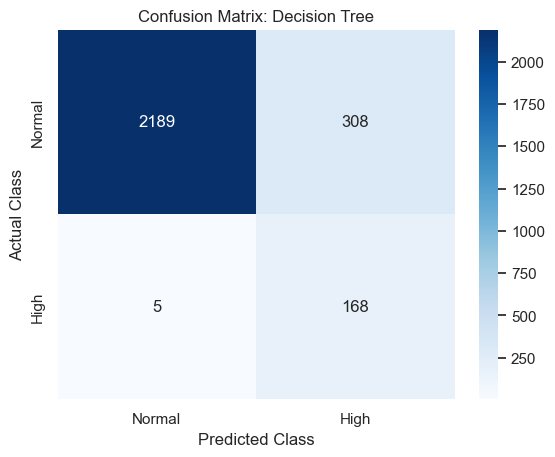

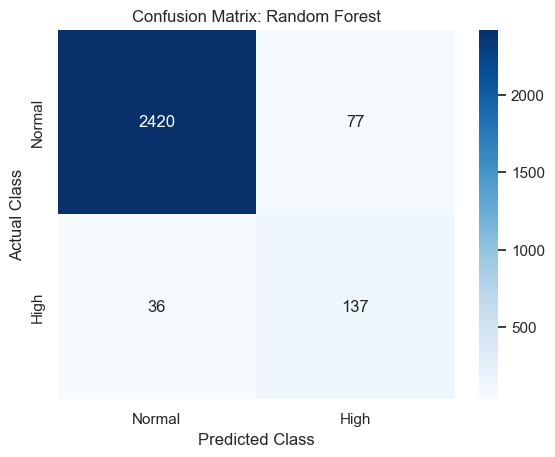

In [159]:
classification_results=[]

for name,predictions in classification_predictions.items():

    classification_results.append({
        "Model":name,
        "Accuracy":accuracy_score(yc_test,predictions),
        "Precision":precision_score(yc_test,predictions,zero_division=0),
        "Recall": recall_score(yc_test, predictions, zero_division=0),
        "F1 Score": f1_score(yc_test, predictions, zero_division=0)})

classification_results=pd.DataFrame(classification_results).sort_values("F1 Score", ascending=False)
display(classification_results)


for name,predictions in classification_predictions.items():

    cm=confusion_matrix(yc_test, predictions, labels=[0, 1])
    sns.heatmap(cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "High"],
        yticklabels=["Normal", "High"])

    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()

Identify the best classification model

In [160]:
best_classifier_name=classification_results.iloc[0]["Model"]
best_classifier=fitted_classifiers[best_classifier_name]
best_class_predictions = classification_predictions[best_classifier_name]

print("Best classification model by test F1 Score:",best_classifier_name)
print(classification_report(yc_test,best_class_predictions,labels=[0, 1],
                            target_names=["Normal Flow", "High Flow"],zero_division=0))

Best classification model by test F1 Score: Random Forest
              precision    recall  f1-score   support

 Normal Flow       0.99      0.97      0.98      2497
   High Flow       0.64      0.79      0.71       173

    accuracy                           0.96      2670
   macro avg       0.81      0.88      0.84      2670
weighted avg       0.96      0.96      0.96      2670



Explain which features contribute most to high-flow prediction

,Feature,Importance
8,num__dew_point_mean_c,0.095248
31,num__month_sin,0.078613
21,num__rain_mm_rolling7_sum,0.073327
24,num__precipitation_mm_rolling7_sum,0.072616
29,num__day_of_year,0.068072
26,num__discharge_lag1,0.059004
27,num__discharge_lag2,0.050986
10,num__relative_humidity_mean_pct,0.044242
5,num__soil_moisture_0_100cm_m3m3,0.043144
28,num__discharge_lag3,0.041239


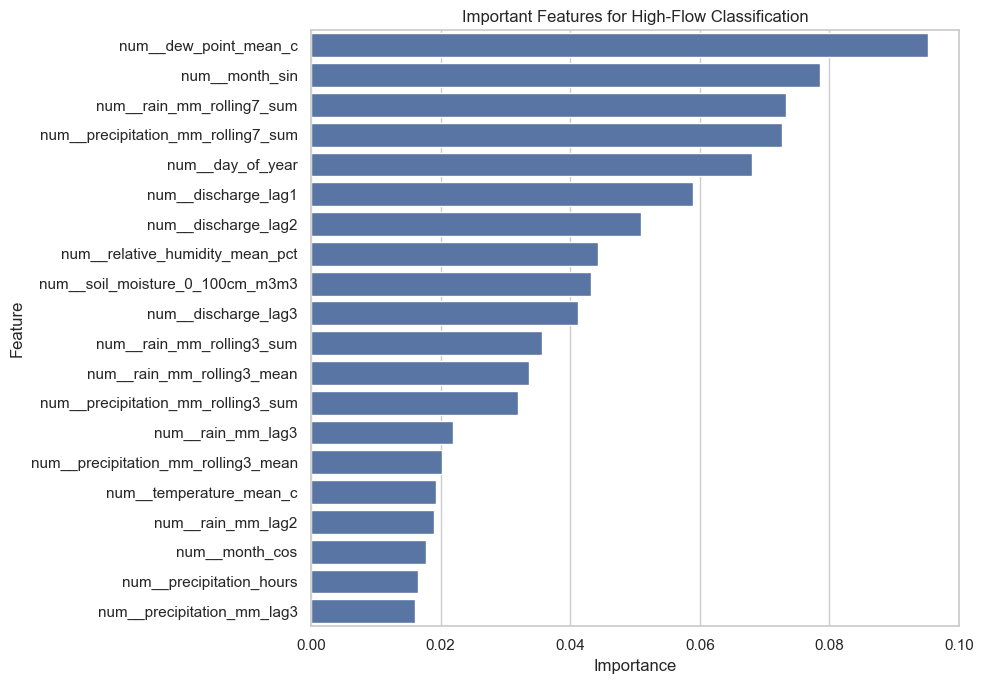

In [161]:
classifier_preprocessor=best_classifier.named_steps["preprocessor"]
classifier_estimator=best_classifier.named_steps["model"]

classifier_feature_names=(classifier_preprocessor.get_feature_names_out())

if hasattr(classifier_estimator,"feature_importances_"):
    classifier_importance_values=(classifier_estimator.feature_importances_)
elif hasattr(classifier_estimator, "coef_"):

    classifier_importance_values=np.abs(
        classifier_estimator.coef_[0])

classifier_importance=pd.DataFrame({"Feature":classifier_feature_names,
    "Importance":classifier_importance_values}).sort_values("Importance",ascending=False)
display(classifier_importance.head(20))

plt.figure(figsize=(10,7))
sns.barplot(data=classifier_importance.head(20),x="Importance",y="Feature")
plt.title("Important Features for High-Flow Classification")
plt.tight_layout()
plt.show()

Q37. Which weather and historical river features are most useful for predicting the next 
day's river discharge

Historical river discharge and rainfall-related features are important candidates for predicting next-day river discharge. Previous-day discharge features (discharge_lag1, discharge_lag2, and discharge_lag3) help the model understand how river flow changes over time. Rainfall lag features and rolling rainfall totals help capture recent rainfall and possible delayed runoff effects.
Other useful variables may include precipitation, soil moisture, relative humidity, temperature, and river station location. The actual importance of each feature depends on the trained model and must be confirmed using the feature-importance results.

In [162]:
print("Top regression features:")
display(feature_importance.head(10))
print("""
Interpretation:
Historical discharge lag features can capture river-flow persistence.
Rainfall lag and rolling rainfall features can represent recent rainfall
and possible delayed runoff effects. Weather, location and station
features may also contribute.

Use the feature-importance table above to identify the actual top
features in your fitted model. Importance does not prove causation.
""")

Top regression features:


,Feature,Importance
26,num__discharge_lag1,0.699207
22,num__rain_mm_rolling3_mean,0.049866
4,num__precipitation_mm,0.041742
6,num__rain_mm,0.033366
23,num__precipitation_mm_rolling3_sum,0.027714
7,num__temperature_mean_c,0.024802
29,num__day_of_year,0.018615
27,num__discharge_lag2,0.017293
20,num__rain_mm_rolling3_sum,0.014511
25,num__precipitation_mm_rolling3_mean,0.012647



Interpretation:
Historical discharge lag features can capture river-flow persistence.
Rainfall lag and rolling rainfall features can represent recent rainfall
and possible delayed runoff effects. Weather, location and station
features may also contribute.

Use the feature-importance table above to identify the actual top
features in your fitted model. Importance does not prove causation.



Q38. Which machine learning model gives the best prediction performance

Answer:
Three regression algorithms are used in this project: Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor.
Their performance is compared using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score. MAE, MSE, and RMSE measure prediction errors, where lower values generally indicate better performance. R² measures how well the model explains variation in the target variable, with higher values generally preferred.
The best-performing model should be selected using the chronological test results, giving particular attention to RMSE and checking MAE and R² as well. The exact winning model cannot be stated until the results from your notebook are available.

In [163]:
display(regression_results)
best_row=regression_results.iloc[0]
print("Best regression model:",best_row["Model"])
print("MAE:",best_row["MAE"])
print("MSE:",best_row["MSE"])
print("RMSE:",best_row["RMSE"])
print("R2 Score:",best_row["R2"])

print("""
The selected model has the lowest test RMSE among the three
models. Check MAE and R² as well before discussing its suitability.
""")

,Model,MAE,MSE,RMSE,R2
2,Gradient Boosting,4.158856,593.713782,24.366243,0.828520
0,Linear Regression,11.659612,606.482933,24.626874,0.824832
1,Random Forest,3.816623,731.510278,27.046447,0.788721


Best regression model: Gradient Boosting
MAE: 4.158855979159137
MSE: 593.7137823372814
RMSE: 24.366242679930803
R2 Score: 0.8285202315146245

The selected model has the lowest test RMSE among the three
models. Check MAE and R² as well before discussing its suitability.



Q39. How much does feature engineering improve the model

Answer:
Feature engineering improves a machine learning model by creating additional information from existing data. In this project, rainfall lag features, rolling rainfall totals, previous-day river discharge, and date features are created to help the model identify temporal patterns.
The improvement is measured by comparing the baseline model's RMSE with the feature-engineered model's RMSE on the same test period.
A positive percentage indicates that the engineered model has lower RMSE. A negative percentage indicates worse performance. The actual percentage must be taken from your notebook's output.

In [164]:
print("Baseline RMSE:",round(baseline_rmse,4))
print("Engineered model RMSE:",round(engineered_rmse,4))

if baseline_rmse>0:
    print("RMSE improvement:",round(improvement,2),"%")
if engineered_rmse < baseline_rmse:
    print("Feature-engineered model improved RMSE.")
elif engineered_rmse > baseline_rmse:
    print("Feature engineering did not improve RMSE in this comparison.")
else:
    print("Both approaches have the same RMSE.")

Baseline RMSE: 28.2216
Engineered model RMSE: 24.3662
RMSE improvement: 13.66 %
Feature-engineered model improved RMSE.


Q40. Which river station is easiest and hardest for the model to predict

Answer:
The prediction performance of each river station is evaluated using its Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).
The station with the lowest MAE is considered the easiest to predict because its average absolute prediction error is the smallest. The station with the highest MAE is considered the hardest to predict because its average absolute prediction error is the largest.
Differences in river-flow variability, rainfall patterns, historical observations, and extreme discharge events may contribute to differences in prediction accuracy between stations.
The names of the easiest and hardest stations must be taken from the station-wise error table generated by your model.

,MAE,RMSE,Number_of_Records
location,,,
Devghat,0.627673,0.740505,267
Bahrabise,0.682560,1.140554,267
Rasuwagadhi,0.803210,0.914767,267
Chatara,0.970410,1.101116,267
Chisapani,1.206592,1.274850,267
Bhada Bridge,1.451186,1.563350,267
Khokana,1.461109,2.099388,267
Chameliya/Nayalbadi,2.377789,3.579008,267
Belsot,2.973417,7.625422,267


Easiest location: Devghat
Lowest MAE: 0.6276730689669432
Hardest location: Kusum
Highest MAE: 29.034614633250207


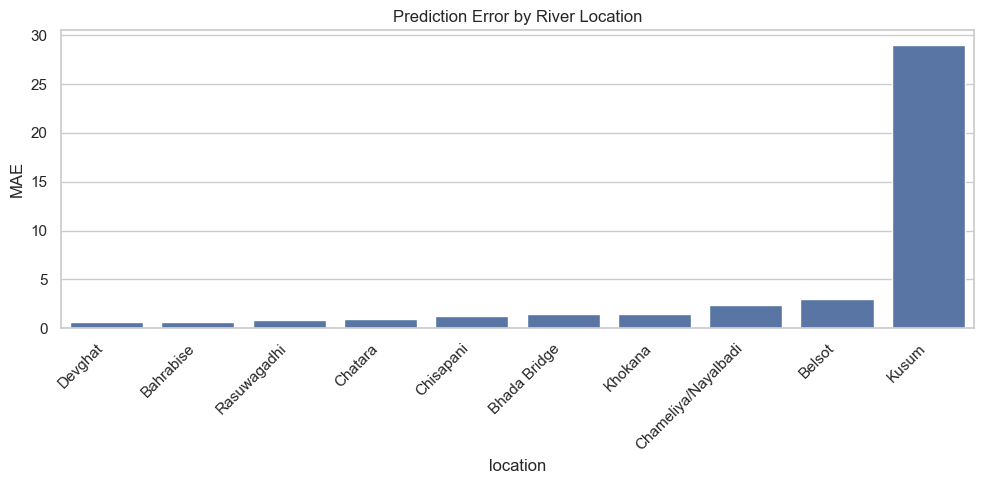

In [165]:
evaluation["absolute_error"]=(evaluation["actual"]-evaluation["predicted"]).abs()

location_errors = evaluation.groupby("location").agg(
    MAE=("absolute_error", "mean"),
    RMSE=("absolute_error",
          lambda s: np.sqrt(np.mean(s ** 2))),
    Number_of_Records=("absolute_error", "count")).sort_values("MAE")

display(location_errors)
print("Easiest location:",location_errors.index[0])
print("Lowest MAE:",location_errors.iloc[0]["MAE"])

print("Hardest location:",location_errors.index[-1])
print("Highest MAE:",location_errors.iloc[-1]["MAE"])
plt.figure(figsize=(10,5))
sns.barplot(data=location_errors.reset_index(),x="location",y="MAE")
plt.xticks(rotation=45,ha="right")
plt.title("Prediction Error by River Location")
plt.tight_layout()
plt.show()

Q41. What are the main patterns you found in rainfall and river discharge


Answer:
The relationship between rainfall and river discharge is analyzed using scatter plots, correlation analysis, and monthly and seasonal comparisons.
Rainfall can contribute to increased river discharge through surface runoff, while soil moisture and previous rainfall may influence how quickly a river responds. However, the relationship may be delayed and can differ between river stations.
Monthly and seasonal analysis helps identify periods with higher average discharge. Unusually high discharge observations are also examined using a percentile-based threshold.
The final conclusions should describe the patterns actually observed in the dataset, including the measured rainfall correlation, the months or seasons with higher discharge, and the locations experiencing unusually high flows. Correlation alone does not prove that rainfall caused a particular discharge event.

In [166]:
# 1. Rainfall and river discharge correlation
correlation=df["rain_mm"].corr(df["river_discharge_m3s"])
print("Rainfall and River Discharge Analysis")
print("-" * 40)
print(f"Pearson correlation: {correlation:.4f}")

if correlation > 0:
    print("Finding: Rainfall and river discharge have a positive linear relationship.")
elif correlation < 0:
    print("Finding: Rainfall and river discharge have a negative linear relationship.")
else:
    print("Finding: No linear correlation was detected.")

if abs(correlation) < 0.3:
    print("Relationship strength: Weak")
elif abs(correlation) < 0.7:
    print("Relationship strength: Moderate")
else:
    print("Relationship strength: Strong")

# 2. Monthly average discharge
monthly=(df.groupby(df["date"].dt.month)["river_discharge_m3s"].mean())

month_names={1:"January",2: "February",3:"March",
             4:"April",5:"May",6:"June",
             7:"July",8:"August",9:"September",
             10:"October",11:"November",12:"December"}

monthly.index=monthly.index.map(month_names)
print("\nMonthly Average River Discharge:")
display(monthly.to_frame("Average Discharge (m³/s)"))

print("Highest average discharge month:",monthly.idxmax())
print("Lowest average discharge month:",monthly.idxmin())

# 3. Seasonal average discharge
def get_season(month):
    if month in [12,1,2]:
        return "Winter"
    elif month in [3,4,5]:
        return "Pre-monsoon"
    elif month in [6,7,8,9]:
        return "Monsoon"
    else:
        return "Post-monsoon"

seasonal_df=df.copy()
seasonal_df["season"]=seasonal_df["date"].dt.month.map(get_season)
seasonal=(seasonal_df.groupby("season")["river_discharge_m3s"].mean().sort_values(ascending=False))

print("\nSeasonal Average River Discharge:")
display(seasonal.to_frame("Average Discharge (m³/s)"))
print("Highest average discharge season:", seasonal.idxmax())
print("Lowest average discharge season:", seasonal.idxmin())

# 4. Identify unusually high discharge observations
threshold=df["river_discharge_m3s"].quantile(0.95)
high_flow=df[df["river_discharge_m3s"] >= threshold
             ].sort_values("river_discharge_m3s",ascending=False)
print(f"\n95th percentile threshold:{threshold:.2f} m³/s")
print("Number of high-discharge records:",len(high_flow))
display(high_flow[["date", "location", "rain_mm", "river_discharge_m3s"]].head(10))

# 5. Automatic conclusion
print("\nPROJECT FINDINGS")
print(f"1. Rainfall-discharge correlation is {correlation:.4f}.")
print(f"2. Highest average discharge occurs in {monthly.idxmax()}.")
print(f"3. Lowest average discharge occurs in {monthly.idxmin()}.")
print(f"4. Highest average seasonal discharge occurs during "f"{seasonal.idxmax()}.")
print(f"5. Lowest average seasonal discharge occurs during "f"{seasonal.idxmin()}.")
print(f"6. The overall 95th percentile discharge threshold is "f"{threshold:.2f} m³/s.")
print(
    "7. These results describe the observed data. Correlation "
    "does not prove causation, and high discharge does not "
    "automatically indicate an official flood warning."
)

Rainfall and River Discharge Analysis
----------------------------------------
Pearson correlation: 0.0997
Finding: Rainfall and river discharge have a positive linear relationship.
Relationship strength: Weak

Monthly Average River Discharge:


,Average Discharge (m³/s)
date,
January,4.309758
February,3.801097
March,3.533565
April,3.200350
May,3.251137
June,6.312908
July,53.719702
August,72.464669
September,52.970000


Highest average discharge month: August
Lowest average discharge month: April

Seasonal Average River Discharge:


,Average Discharge (m³/s)
season,
Monsoon,46.226443
Post-monsoon,18.840557
Winter,4.343382
Pre-monsoon,3.329742


Highest average discharge season: Monsoon
Lowest average discharge season: Pre-monsoon

95th percentile threshold:90.41 m³/s
Number of high-discharge records: 673


,date,location,rain_mm,river_discharge_m3s
6368,2024-09-28,Kusum,8.4,3175.87
6378,2024-09-29,Kusum,0.9,2359.48
2374,2023-07-04,Kusum,5.6,1802.02
5538,2024-07-07,Kusum,82.0,1736.80
5528,2024-07-06,Kusum,60.9,1609.65
2371,2023-07-01,Kusum,25.8,1421.33
5548,2024-07-08,Kusum,10.2,1418.06
9568,2025-08-14,Kusum,4.9,1190.24
2375,2023-07-05,Kusum,0.8,1182.04
9478,2025-08-05,Kusum,15.2,1173.90



PROJECT FINDINGS
1. Rainfall-discharge correlation is 0.0997.
2. Highest average discharge occurs in August.
3. Lowest average discharge occurs in April.
4. Highest average seasonal discharge occurs during Monsoon.
5. Lowest average seasonal discharge occurs during Pre-monsoon.
6. The overall 95th percentile discharge threshold is 90.41 m³/s.
7. These results describe the observed data. Correlation does not prove causation, and high discharge does not automatically indicate an official flood warning.


Q42. What are the limitations of your prediction mode

Answer:
The Nepal Flood and Weather Analysis model has several limitations:

1.Historical data dependency: The model learns from past observations and may not predict unprecedented flood events accurately.

2.Data quality: Inaccurate measurements or limited monitoring coverage can affect prediction performance.

3.Delayed rainfall effects: Rainfall may influence river discharge after a delay, and this delay can vary by location.

4.Extreme events: The model may perform less accurately during unusually high discharge events if similar events are insufficiently represented in the training data.

5.Station differences: Different river stations may have different hydrological characteristics, which can affect prediction accuracy.

6.Weather forecast availability: The model must use information available at prediction time. Actual future weather observations cannot be assumed to be known in advance.

7.Model generalization: Performance on the test period may not represent performance during all future seasons or extreme weather conditions.

8.High-flow classification: The station-specific 90th-percentile threshold is a statistical definition of high flow, not an official flood-warning level.

In [167]:
# Create output folder
os.makedirs("nepal_flood_outputs", exist_ok=True)

# Save processed data and evaluation results
model_df.to_csv("nepal_flood_outputs/cleaned_feature_engineered_dataset.csv",index=False)

regression_results.to_csv("nepal_flood_outputs/regression_model_comparison.csv",index=False)

classification_results.to_csv("nepal_flood_outputs/classification_model_comparison.csv",index=False)

evaluation.to_csv("nepal_flood_outputs/regression_predictions_and_errors.csv",index=False)

location_errors.to_csv("nepal_flood_outputs/location_prediction_errors.csv")

# Save models
joblib.dump(best_model,"nepal_flood_outputs/best_regression_model.joblib")

joblib.dump(best_classifier,"nepal_flood_outputs/best_high_flow_classifier.joblib")

# Save high-flow thresholds
pd.Series(station_thresholds,name="high_flow_threshold_m3s"
          ).to_csv("nepal_flood_outputs/high_flow_thresholds.csv")

print("All deliverables saved in nepal_flood_outputs/")

print("""
MODEL LIMITATIONS

1. The model learns patterns from historical data and may not
   predict unprecedented flood events accurately.
2. Prediction quality depends on the quality and coverage of
   weather observations and river-discharge measurements.
3. Rainfall effects may be delayed and differ by river station.
4. A station-specific 90th-percentile threshold is a statistical
   high-flow label, not an official flood-warning threshold.
5. Feature importance and correlation do not establish causation.
6. Test performance may change when the model is applied to
   future periods or unusual weather conditions.
7. If future weather forecasts are unavailable, the model cannot
   assume future rainfall observations are already known.
""")

All deliverables saved in nepal_flood_outputs/

MODEL LIMITATIONS

1. The model learns patterns from historical data and may not
   predict unprecedented flood events accurately.
2. Prediction quality depends on the quality and coverage of
   weather observations and river-discharge measurements.
3. Rainfall effects may be delayed and differ by river station.
4. A station-specific 90th-percentile threshold is a statistical
   high-flow label, not an official flood-warning threshold.
5. Feature importance and correlation do not establish causation.
6. Test performance may change when the model is applied to
   future periods or unusual weather conditions.
7. If future weather forecasts are unavailable, the model cannot
   assume future rainfall observations are already known.



## Short Summary of Key Findings and Conclusions
The Nepal Flood and Weather Analysis project aimed to predict the next day's river discharge using historical river data, rainfall, weather conditions, and location information.

Data preprocessing was performed to check missing values, duplicate records, and data types. Exploratory Data Analysis (EDA) was used to examine rainfall-discharge relationships, differences between river stations, monthly and seasonal discharge patterns, and unusually high discharge observations.

Feature engineering created rainfall lag features, rolling rainfall totals, previous-day discharge features, and date-related variables. Three regression models—Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor—were trained and compared using MAE, MSE, RMSE, and R² score. A chronological train-test split was used to evaluate predictions on later observations.

The project also included a high-flow classification task using Logistic Regression, Decision Tree, and Random Forest classifiers. Classification performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

Conclusion: This project demonstrates how data analysis and machine learning can help identify river-discharge patterns and forecast next-day river flow. The best-performing model, most important features, and improvement from feature engineering should be identified from the actual evaluation results. The model can support analytical understanding but should not replace official flood-warning systems.